In [71]:
load("visualize.sage")
load("surfaces.sage")
load("curves.sage")
load("subresultants.sage")

In [26]:
degree = 6
order = '3+2'

v=['a%d' % i for i in xrange(degree +1)]
v.append('t')
R=PolynomialRing(QQ, v)
R.inject_variables()
poly = sum([R('a%d' %i) *t ^i for i in range(degree +1)]).polynomial(t)

poly_d = poly.derivative()

S0 = subrescoefs(poly, poly_d, 0)
S1 = subrescoefs(poly, poly_d, 1)
S2 = subrescoefs(poly, poly_d, 2)
S3 = subrescoefs(poly, poly_d, 3)


# disc:

dS = load('discriminants/disc2_2')
sub_dict = dict(zip((dS.ring()).gens(),S2))
S2disc_2 = dS.substitute(sub_dict)

dS = load('discriminants/disc3_3')
sub_dict = dict(zip((dS.ring()).gens(),S3))
S3disc_3 = dS.substitute(sub_dict)

dS = load('discriminants/disc3_2')
sub_dict = dict(zip((dS.ring()).gens(),S3))
S3disc_2 = dS.substitute(sub_dict)


if order == '2':
    disc = ideal(S0).saturation(ideal(S0[0].variables()[-1]))[0]

if order == '3':
    disc = ideal(S0)+ideal(S1)+S2disc_2
    disc = disc.saturation(S2[0])[0]
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]

if order == '2+2':
    disc = ideal(S0[0])+ideal(S1)
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S2disc_2)[0]
    
if order == '4':
    disc = ideal(S0)+ideal(S1)+ideal(S2)+S3disc_3
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S3[0])[0]
    
if order == '3+2':
    disc = ideal(S0)+ideal(S1)+ideal(S2)+S3disc_2
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S3disc_3)[0]
    disc = disc.saturation(S3[0])[0]

if order == '2+2+2':
    disc = ideal(S0)+ideal(S1)+ideal(S2)
    disc = disc.saturation(ideal(S0[0].variables()[-1]))[0]
    disc = disc.saturation(S3disc_2)[0]
    

#nodal,cuspidal = nodal_and_cuspidal_discriminant_ideals(degree)

print disc

#print nodal.saturation(ideal(S0[0].variables()[-1]))[0]==disc

disc.save("discriminants/disc%d_%s" %(degree,order))

Defining a0, a1, a2, a3, a4, a5, a6, t
Ideal (a2^2*a4^2 - 3*a1*a3*a4^2 + 12*a0*a4^3 - 3*a2^2*a3*a5 + 9*a1*a3^2*a5 + a1*a2*a4*a5 - 45*a0*a3*a4*a5 - 20*a1^2*a5^2 + 75*a0*a2*a5^2 + 12*a2^3*a6 - 45*a1*a2*a3*a6 + 81*a0*a3^2*a6 + 75*a1^2*a4*a6 - 126*a0*a2*a4*a6 - 135*a0*a1*a5*a6 + 405*a0^2*a6^2, a2^2*a3*a4*a5 - 3*a1*a3^2*a4*a5 + 12*a0*a3*a4^2*a5 - 9*a2^3*a5^2 + 32*a1*a2*a3*a5^2 - 45*a0*a3^2*a5^2 - 36*a1^2*a4*a5^2 + 20*a0*a2*a4*a5^2 + 100*a0*a1*a5^3 - 9*a2^2*a3^2*a6 + 27*a1*a3^3*a6 + 32*a2^3*a4*a6 - 111*a1*a2*a3*a4*a6 + 27*a0*a3^2*a4*a6 + 135*a1^2*a4^2*a6 - 96*a0*a2*a4^2*a6 - 2*a1*a2^2*a5*a6 - 60*a1^2*a3*a5*a6 + 243*a0*a2*a3*a5*a6 - 378*a0*a1*a4*a5*a6 - 225*a0^2*a5^2*a6 + 75*a1^2*a2*a6^2 - 288*a0*a2^2*a6^2 + 135*a0*a1*a3*a6^2 + 864*a0^2*a4*a6^2, a1*a2*a3*a4*a5 - 9*a0*a3^2*a4*a5 - 9*a1^2*a4^2*a5 + 32*a0*a2*a4^2*a5 - 9*a1*a2^2*a5^2 + 32*a1^2*a3*a5^2 - 15*a0*a2*a3*a5^2 - 110*a0*a1*a4*a5^2 + 375*a0^2*a5^3 - 9*a1*a2*a3^2*a6 + 81*a0*a3^3*a6 + 32*a1*a2^2*a4*a6 - 15*a1^2*a3*a4*a6 - 288*a0*a2*a3*a4*a6

# Plane curves

We consider a general curve $\mathbb P^2$ of degree $d$.

Ideal (x0^4 + 2*x0^3*x1 - 4*x0^2*x1^2 - x0*x1^3 + x1^4 + x0^3*x2 + 71*x0^2*x1*x2 + x0*x1^2*x2 + 15*x1^3*x2 - x0^2*x2^2 + x1^2*x2^2 + x0*x2^3 + x1*x2^3 + 4*x2^4) of Multivariate Polynomial Ring in x0, x1, x2 over Rational Field


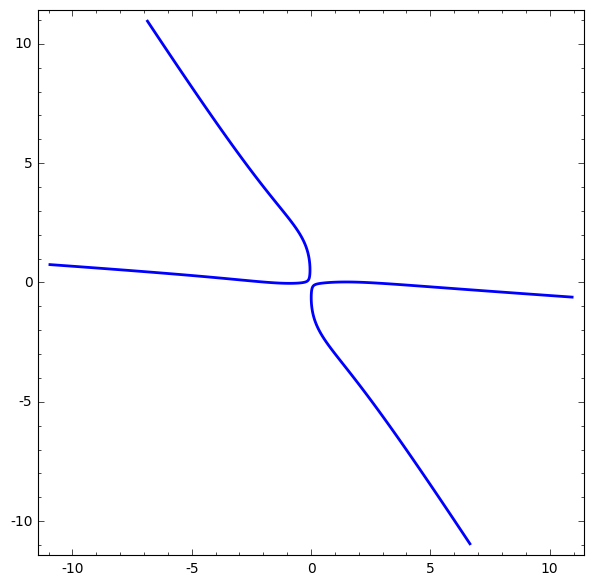

In [93]:
R.<x0,x1,x2> = QQ[]

degree = 4

F = general_curve(degree)
print F

g = plot_curve(F)
g.show()

### Inflectional and double tangents
We compute inflectional points and lines using the hessian determinant.

Number of complex flexes:  24
Number of real flexes:  4


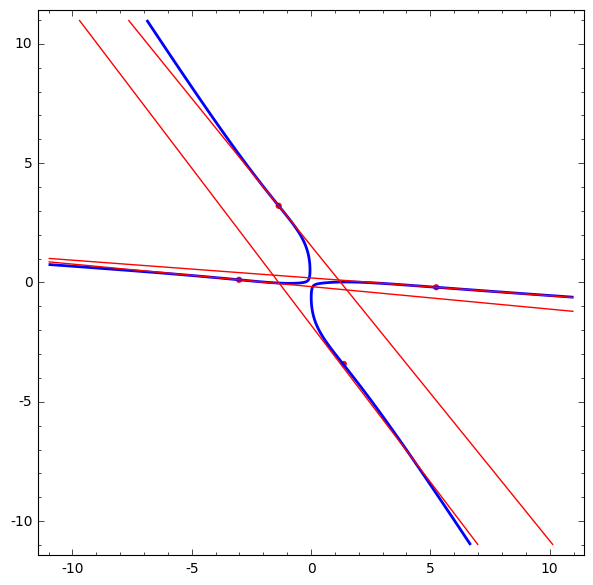

In [94]:
R.<x0,x1,x2> = QQ[]
flex_points_ideal = F + hessian_determinant_curve(F)

print "Number of complex flexes: ", flex_points_ideal.hilbert_polynomial()

# real flex points:
real_flex_points = (flex_points_ideal.subs(x0=1).change_ring(QQ[x1, x2])).variety(RR)
print "Number of real flexes: ", len(real_flex_points)

# compute and show real flex lines
lines=tangents_at_points(F,real_flex_points)

g = plot_curve(F)
g += plot_lines(lines)
g += plot_points(real_flex_points)
g.show()

Number of complex double lines:  14
Number of real double lines:  4


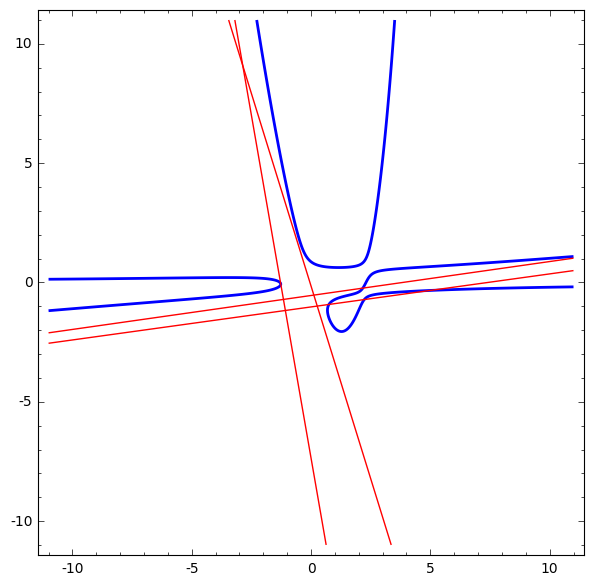

In [80]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]

c=poly.polynomial(t).coefficients()

sub_dict = dict(zip(nodal.ring().gens(),c))

#double_lines = nodal.subs(a0=c[0],a1=c[1],a2=c[2],a3=c[3],a4=c[4]) # change
double_lines = nodal.subs(sub_dict)
double_lines = double_lines.change_ring(R2)

R2.<u0,u1,u2> = QQ[]
double_lines = double_lines.saturation(ideal(u1))[0]

print "Number of complex double lines: ", double_lines.hilbert_polynomial()

real_double_lines = (double_lines.subs(u0=1).change_ring(QQ[u1, u2])).variety(RR)
print "Number of real double lines: ", len(real_double_lines)

if True:
    lines = []
    for l in real_double_lines:
        lines.append([1,l['u1'],l['u2']])

    R.<x1,x2> = QQ[]
    g = plot_curve(F)
    for l in lines:
        line_equation = ideal(l[0] +l[1] *x1 +l[2] *x2).change_ring(RR[x1, x2])
        g += line_equation.plot(color='red')
    g.show()

### Dual curve
We can compute the *dual curve* using a similar procedure.

 Degree of dual:  12
Ideal (125*u0^12 + 3322*u0^11*u1 + 45403*u0^10*u1^2 + 439584*u0^9*u1^3 + 2774795*u0^8*u1^4 + 9582650*u0^7*u1^5 + 14321749*u0^6*u1^6 - 3145692*u0^5*u1^7 - 32147084*u0^4*u1^8 - 22453576*u0^3*u1^9 + 5943704*u0^2*u1^10 + 552832*u0*u1^11 - 3979776*u1^12 - 38146*u0^11*u2 - 451952*u0^10*u1*u2 - 5458260*u0^9*u1^2*u2 - 35204428*u0^8*u1^3*u2 - 102439650*u0^7*u1^4*u2 - 101308816*u0^6*u1^5*u2 + 103296652*u0^5*u1^6*u2 + 269942624*u0^4*u1^7*u2 + 100334776*u0^3*u1^8*u2 - 58580480*u0^2*u1^9*u2 + 24826016*u0*u1^10*u2 + 47987616*u1^11*u2 + 74463*u0^10*u2^2 + 461120*u0^9*u1*u2^2 + 6877337*u0^8*u1^2*u2^2 + 46629212*u0^7*u1^3*u2^2 + 111296654*u0^6*u1^4*u2^2 + 38463170*u0^5*u1^5*u2^2 - 147807952*u0^4*u1^6*u2^2 - 21011200*u0^3*u1^7*u2^2 + 128639268*u0^2*u1^8*u2^2 - 188007408*u0*u1^9*u2^2 - 213637472*u1^10*u2^2 + 40262*u0^9*u2^3 + 944478*u0^8*u1*u2^3 + 8578366*u0^7*u1^2*u2^3 + 27678842*u0^6*u1^3*u2^3 + 1647776*u0^5*u1^4*u2^3 - 170396588*u0^4*u1^5*u2^3 - 344168496*u0^3*u1^6*u2^3 - 12191421

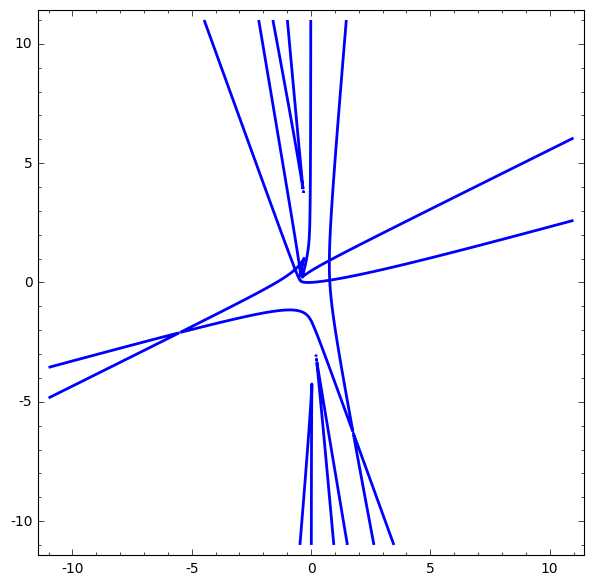

In [82]:
R2.<u0,u1,u2> = QQ[]
R3.<x0, x1, x2, u0, u1, u2, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector([-u1, u0, 0])
Q = vector([0, -u2, u1])

F1 = F.change_ring(R3)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), x2=((P + t * Q)[2]))).gens()[0]
dual_curve_p = poly.discriminant(t)
dual_curve = ideal(dual_curve_p) #.change_ring(R2)

dual_curve = dual_curve.saturation(ideal(u1))[0]


print "Degree of dual: ", dual_curve.gens()[0].degree()
print dual_curve
g = plot_curve(dual_curve)
g.show()

### Summary

In [81]:
print "The curve defined by \n", F.gens()[0]
print "Degree: ", degree
print "Degree of dual: ", dual_curve.gens()[0].degree()
print "Inflection points (complex/real): ", flex_points_ideal.hilbert_polynomial(), len(real_flex_points)
print "Bitangents (complex/real): ", double_lines.hilbert_polynomial(), len(real_double_lines)

The curve defined by 
6*x0^4 + 2*x0^3*x1 - 2*x0^2*x1^2 + 3*x0*x1^2*x2 - x1^3*x2 - x0^2*x2^2 - 24*x0*x1*x2^2 + 11*x1^2*x2^2 - 8*x0*x2^3 + x1*x2^3
Degree:  3
Degree of dual: 

AttributeError: 'function' object has no attribute 'gens'

# Surfaces in $\mathbb P^3$
We consider a general surface $S$ in $\mathbb P^3$ defined by a polynomial $F \in \mathbb R[x_0,x_1,x_2,x_3]$ of degree $d$.

In [84]:
K = QQ#GF(9973)
R.<x0,x1,x2,x3> = K['x0,x1,x2,x3']
X = matrix(R,[[x0],[x1],[x2],[x3]])

degree = 4

S_F = general_surface(degree)
F = S_F.gens()[0] 

print F

x0^4 - 2*x0^3*x1 + x0^2*x1^2 + 15*x0*x1^3 - 3*x1^4 + 4*x0^3*x2 - x0^2*x1*x2 - 2*x1^3*x2 + 4*x0^2*x2^2 - 6*x0*x1*x2^2 - 6*x1^2*x2^2 - x0*x2^3 + 3*x1*x2^3 + 2*x2^4 - 2*x0^3*x3 + x0^2*x1*x3 - 3*x0*x1^2*x3 - 45*x0^2*x2*x3 + 21*x0*x1*x2*x3 - 3*x1^2*x2*x3 - x0*x2^2*x3 + 2*x1*x2^2*x3 - 6*x2^3*x3 + x0^2*x3^2 + 40*x0*x1*x3^2 - x1^2*x3^2 + x0*x2*x3^2 + x1*x2*x3^2 - 2*x2^2*x3^2 - x0*x3^3 - 4*x1*x3^3 - x2*x3^3


In [86]:
plot_surf(F)

### Image contour
We observe the surface with a perspective projection.

Ideal (u0^12 - 18*u0^11*u1 + 23*u0^10*u1^2 - 6*u0^9*u1^3 - 20*u0^8*u1^4 + 6*u0^7*u1^5 + 23*u0^6*u1^6 - 23*u0^5*u1^7 + 19*u0^4*u1^8 + 2*u0^3*u1^9 - 26*u0^2*u1^10 - 18*u0*u1^11 + 26*u1^12 - 3*u0^11*u2 - 13*u0^10*u1*u2 + 5*u0^9*u1^2*u2 - 21*u0^8*u1^3*u2 + 16*u0^7*u1^4*u2 - 13*u0^6*u1^5*u2 + 10*u0^5*u1^6*u2 + 17*u0^4*u1^7*u2 + 21*u0^3*u1^8*u2 + 26*u0^2*u1^9*u2 - 5*u0*u1^10*u2 + 13*u1^11*u2 - 25*u0^10*u2^2 - u0^9*u1*u2^2 - 10*u0^8*u1^2*u2^2 + 25*u0^7*u1^3*u2^2 + 22*u0^6*u1^4*u2^2 - 22*u0^5*u1^5*u2^2 + 14*u0^4*u1^6*u2^2 - 14*u0^3*u1^7*u2^2 + 10*u0^2*u1^8*u2^2 + 9*u0*u1^9*u2^2 + 6*u1^10*u2^2 - 26*u0^9*u2^3 - 26*u0^8*u1*u2^3 + 6*u0^7*u1^2*u2^3 + 11*u0^6*u1^3*u2^3 - 10*u0^5*u1^4*u2^3 + 26*u0^4*u1^5*u2^3 - 3*u0^3*u1^6*u2^3 + 26*u0^2*u1^7*u2^3 - 12*u0*u1^8*u2^3 + 19*u1^9*u2^3 - 12*u0^8*u2^4 - 20*u0^7*u1*u2^4 + 14*u0^6*u1^2*u2^4 + 16*u0^5*u1^3*u2^4 + 21*u0^4*u1^4*u2^4 - 6*u0^3*u1^5*u2^4 + 26*u0^2*u1^6*u2^4 + 11*u0*u1^7*u2^4 - 9*u1^8*u2^4 + 10*u0^7*u2^5 + 25*u0^6*u1*u2^5 - 19*u0^5*u1^2*u2^5 - 17*u0

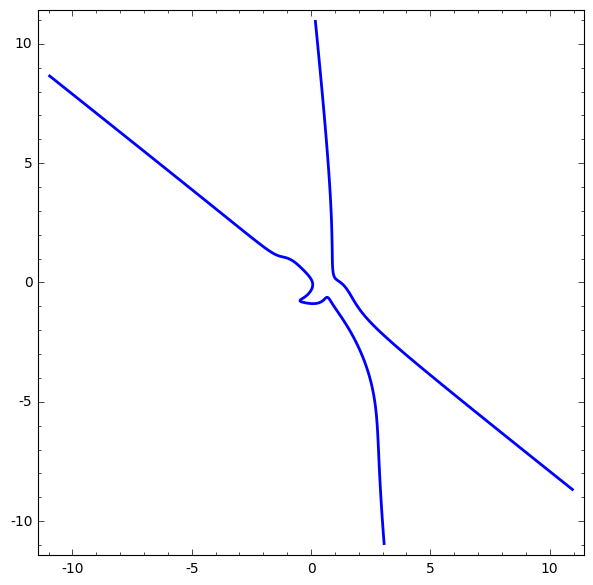

In [22]:
R2.<x0,x1,x2,x3,u0,u1,u2> = K['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
proj_matrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])


X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S_F = S_F.change_ring(R2)

#incidence_ideal = S_F + ideal((proj_matrix*X).augment(U).minors(2))
incidence_ideal = S_F + ideal((proj_matrix*X-U).list())

ramification = incidence_ideal + ideal(jacobian(incidence_ideal.gens(),(x0,x1,x2,x3)).minors(4))

outline = ramification.saturation(ideal(x0, x1, x2, x3))[0]
outline = outline.elimination_ideal((x0, x1, x2, x3))

print outline

g = plot_curve(outline)
g.show()

### Hurwitz complex
The Hurwitz complex is the union of tangent lines.

In [88]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = K[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[1,0,-p12,-p13])
Q = vector(R1,[0, 1, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]

c=poly.polynomial(t).coefficients()

disc=load('discriminants/disc4_2')
v = disc.ring().gens()
disc = disc.change_ring(K[v])
sub_dict = dict(zip((disc.ring()).gens(),c))
hurwitz = (disc.subs(sub_dict)).change_ring(R1)

hurwitz = hurwitz + ideal(1*p23-p02*p13+p03*p12) #.change_ring(R2)


#hurwitz = hurwitz.saturation(ideal(p01))[0]
hurwitz = ideal(hurwitz.groebner_basis())
#hurwitz = (hurwitz.homogenize(p01)).change_ring(QQ[p01, p02, p03, p12, p13, p23])

print "Degree of Hurwitz: ", hurwitz.gens()[0].degree()
print hurwitz

Degree of Hurwitz:  12
Ideal (p02^12 - 465780/8069*p02^11*p03 + 5213894/8069*p02^10*p03^2 - 40187408/8069*p02^9*p03^3 + 204070447/8069*p02^8*p03^4 - 338713416/8069*p02^7*p03^5 - 88706844/8069*p02^6*p03^6 - 51860880/8069*p02^5*p03^7 + 2537411/8069*p02^4*p03^8 + 549148/8069*p02^3*p03^9 - 8522/8069*p02^2*p03^10 - 1344/8069*p02*p03^11 - 23/8069*p03^12 - 166936/8069*p02^11*p12 + 442092/8069*p02^10*p12^2 + 400378/8069*p02^9*p12^3 - 3004364/8069*p02^8*p12^4 + 3338410/8069*p02^7*p12^5 + 35611/8069*p02^6*p12^6 - 2499768/8069*p02^5*p12^7 + 4671750/8069*p02^4*p12^8 - 3966926/8069*p02^3*p12^9 - 3911751/8069*p02^2*p12^10 + 3775626/8069*p02*p12^11 - 552987/8069*p12^12 + 3668178/8069*p02^11*p13 - 38849702/8069*p02^10*p03*p13 + 260397094/8069*p02^9*p03^2*p13 - 912907066/8069*p02^8*p03^3*p13 + 652937212/8069*p02^7*p03^4*p13 + 1563163388/8069*p02^6*p03^5*p13 + 560616180/8069*p02^5*p03^6*p13 + 181100092/8069*p02^4*p03^7*p13 - 5686622/8069*p02^3*p03^8*p13 - 1332166/8069*p02^2*p03^9*p13 + 8950/8069*p02*p03

### Event surfaces
We compute a representation of the flecnodal surface as a curve in ${\rm Gr}(1,\mathbb P^3)$.

In [89]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = K[]

event_type = '4'

P = vector(R1,[1,0,-p12,-p13])
Q = vector(R1,[0, 1, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]


c=poly.polynomial(t).coefficients()
disc=load("discriminants/disc%d_%s" %(degree,event_type))
v = disc.ring().gens()
disc = disc.change_ring(K[v])

sub_dict = dict(zip((disc.ring()).gens(),c))


event_surface = (disc.subs(sub_dict)).change_ring(R1)
event_surface = ideal(event_surface)+ideal(1*p23-p02*p13+p03*p12) #.change_ring(R2)

#flecnodal = flecnodal.saturation(ideal(p01))[0]
event_surface = ideal(event_surface.groebner_basis())


event_surface = (event_surface.homogenize(p01)).change_ring(K[p01, p02, p03, p12, p13, p23])
print "Degree of Surface: ", event_surface.hilbert_polynomial().coefficients()[1]
#print event_surface

Degree of Surface:  80


In [90]:
print event_surface

Ideal (3470068547579039850847816304418573971677557618172978514611571457141840234568798074714197635097628047465884628376259470764671530669773423185590074609551619651350552969848454597582246477666453607334325015034767236691799979625964367992046258654355032350641870468654686150923458981213075846199548186796027608179459518458881162862707033229939291205241755845550051850565608971381821566601538859691503323/2070439479959173165840902312046106772310951264140122023274866602759586549855299832543793590735218402950524041205615390174681395030223299732103390460775723174634725089486233747882334149724193496727701560626213518650215589894487730551214314357858516961997188846318229856138956137554793327259146760024843692901909491760852972768894271778756377806735878230702800450288723049584763422915309223233795*p01^7 - 831905972228202948663606904704603082440006362648261633665557773072470979445298808159019439853286942487834942026830929244526948107597235741159858233850588040625602513962252304927034995707476067

We can also look at the dual $S^\vee$ in $(\mathbb P^3)^*$.

In [ ]:
R1.<x0,x1,x2,x3,u0,u1,u2,u3> = QQ['x0,x1,x2,x3,u0,u1,u2,u3']
Dual = dual_surface(S, R1)
Dual

We consider the outline of $S$ from a viewpoint $c$.

In [68]:
R2.<x0,x1,x2,x3,u0,u1,u2> = K['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S = (ideal(F)).change_ring(R2)

#IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

Outline = Outline.subs(u0=1).change_ring(QQ['u1,u2'])

s = singular.eval
s('LIB "surf.lib";')
#s("ring r = 0,(u1,u2),dp;")
#s("plot("+str(Outline.gens()[0])+")")

#Outline.plot()

print Outline


Ideal (-4741*u1^10 + 3562*u1^9*u2 + 1166*u1^8*u2^2 + 507*u1^7*u2^3 - 4785*u1^6*u2^4 + 3389*u1^5*u2^5 + 4957*u1^4*u2^6 + 1927*u1^3*u2^7 - 1997*u1^2*u2^8 - 1046*u1*u2^9 + 656*u2^10 + 4182*u1^9 + 4762*u1^8*u2 + 2511*u1^7*u2^2 - 2460*u1^6*u2^3 - 2814*u1^5*u2^4 - 1730*u1^4*u2^5 + 4122*u1^3*u2^6 - 4813*u1^2*u2^7 - 2351*u1*u2^8 + 3938*u2^9 - 3568*u1^8 - 4955*u1^7*u2 + 1690*u1^6*u2^2 + 1880*u1^5*u2^3 - 3035*u1^4*u2^4 - 1968*u1^3*u2^5 - 4284*u1^2*u2^6 + 2117*u1*u2^7 + 2753*u2^8 + 2972*u1^7 - 243*u1^6*u2 - 1589*u1^5*u2^2 + 2133*u1^4*u2^3 + 1591*u1^3*u2^4 - 1965*u1^2*u2^5 + 3411*u1*u2^6 - 3666*u2^7 + 952*u1^6 + 435*u1^5*u2 + 3874*u1^4*u2^2 + 2648*u1^3*u2^3 + 601*u1^2*u2^4 + 3126*u1*u2^5 + 252*u2^6 - 1826*u1^5 + 4088*u1^4*u2 - 2165*u1^3*u2^2 + 4921*u1^2*u2^3 - 1835*u1*u2^4 + 796*u2^5 + 1440*u1^4 + 4294*u1^3*u2 + 655*u1^2*u2^2 - 2925*u1*u2^3 + 2094*u2^4 + 2568*u1^3 + 2968*u1^2*u2 - 4090*u1*u2^2 + 2624*u2^3 - 3660*u1^2 - 465*u1*u2 - 1956*u2^2 + 2635*u1 - 4193*u2 + 1) of Multivariate Polynomial Ring 

We now consider a *variable* viewpoint $c$.

In [70]:
R3.<x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3> = K['x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3']

P = vector([c0,c1,c2,c3])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])

X = matrix(R3, [[x0], [x1], [x2], [x3]])
U = matrix(R3, [[u0],[u1],[u2]])
S = (ideal(F)).change_ring(R3)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
#IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(3))

Outline = Ramification.substitute(x0=1,u0=1,c0=1)


#Outline = Ramification.saturation(ideal(x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x1, x2, x3))

print dimension(Outline.substitute(c1=0,c2=0,c3=0).change_ring(K[u1,u2]))
print Outline


KeyboardInterrupt: 

In [ ]:
s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(x,y),dp;")
s("plot(x^2-y^3)")

In [209]:
maxima.plot2d('cos(2*x) + 2*exp(-x)','[x,0,1]','[plot_format,openmath]')

In [2]:
2+2

4

[   1 1/20    0    0]
[   0 1/20    1    0]
[   0    0    0    1]
Ideal (1638400000000*u0^6*u2^2 - 4915200000000*u0^4*u1*u2^3 - 150680960000*u0^4*u2^4 + 4915200000000*u0^2*u1^2*u2^4 - 29134080000*u0^3*u2^5 + 39155200000*u0^2*u1*u2^5 - 1638400000000*u1^3*u2^5 - 2206216400*u0^2*u2^6 + 3939840000*u0*u1*u2^6 - 1848320000*u1^2*u2^6 - 77513076*u0*u2^7 + 108918716*u1*u2^7 - 1073141*u2^8) of Multivariate Polynomial Ring in x, y, z, t, u0, u1, u2 over Rational Field


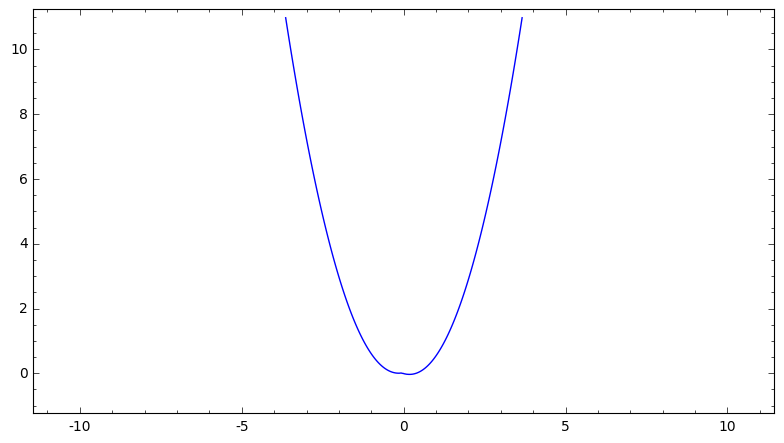

In [318]:
R.<x,y,z,t,u0,u1,u2>=QQ[]
surface = z-(x^2+x*y+y^4)
#s = singular.eval
#s('LIB "surf.lib";')
#s("ring r = 0,(x,y,z),dp;")
#s("surfer(" + str(surface) + ")")

surface_h = surface.homogenize(t)

X = matrix(R, [[x], [y], [z], [t]])
U = matrix(R, [[u0],[u1],[u2]])

# projection:
s=.05
r=10
proj_matrix = matrix(QQ, [[1,s,0,0],[0,s,1,0],[0,0,0,1]])
print(proj_matrix)

incidence = surface_h + ideal((proj_matrix*X).augment(U).minors(2))
incidence = surface_h + ideal(((proj_matrix*X)-U).list())

ramification = incidence + ideal(jacobian(incidence.gens(),(x,y,z,t)).minors(4))

outline = ramification.saturation(ideal(x,y,z,t))[0]
outline = outline.elimination_ideal((x,y,z,t))

print(outline)
outline=outline.subs(u2=1)
(outline.change_ring(QQ[u0,u1])).plot(plot_points=1000)#,algorithm='surf')

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
outline=outline.subs

In [142]:
sines = [plot(c*sin(x), (-2*pi,2*pi), color=Color(c,0,0), ymin=-1, ymax=1) for c in sxrange(0,1,.2)]
a = animate(sines)
a.save('test_animation.gif')

In [150]:
R.<x,y>=QQ[]
curve = ideal(y-x^3)
curve.plot(algorithm="surf",linewidth=50)

In [328]:
# condition for a polynomial to have 2+2 multiplicity/ have 3 multiplicity/ 

# for surfaces: conditions for a polynomial to have 4 multiplicity (flecnodal)
# have 3+2, 2+2+2 (ok). Intersection with plane: 3+ramification on y, 2+2+ramification on y

In [81]:
# subresultant
R.<s,t>=QQ[]

poly0 = s^2*t^4+t+3 
poly1 = s*t^3+s*t^2

poly0=poly0.polynomial(t)
poly1=poly1.polynomial(t)


print subresultant_2(poly0,poly1)

#show(poly.sylvester_matrix(poly.derivative(t), t))

subres = (poly.sylvester_matrix(poly.derivative(t), t)).delete_rows([2,6])
subres = subres.delete_columns([6])
#show(subres)

subres.nrows(),subres.ncols()

condition1 = subres.delete_columns([5]).determinant()
condition2 = subres.delete_columns([4]).determinant()

(3*s^2, s^2, s^4)


In [67]:
M=poly0.sylvester_matrix(poly1)
M.delete_rows?

In [ ]:
(poly0.sylvester_matrix(poly1)).delete_rows

In [62]:
poly0.sylvester_matrix(poly1).delete_rows(?)

SyntaxError: invalid syntax (<ipython-input-62-7debf33a83f8>, line 1)

In [ ]:
poly0.sylvester_matrix(poly1).delete_rows

In [4]:
R.<d>=QQ[]
S.<t1,t2>=R[]

In [20]:
d*t1*((d-1)*t1+t2)*((d-2)*t1+2*t2)#*((d-3)*t1+3*t2)

(d^3 - 3*d^2 + 2*d)*t1^3 + (3*d^2 - 4*d)*t1^2*t2 + 2*d*t1*t2^2

TypeError: no conversion of this ring to a Singular ring defined

In [227]:
load("nodal3.sobj")

Ideal (a3^3 - 4*a2*a3*a4 + 8*a1*a4^2, a2*a3^2 - 4*a2^2*a4 + 2*a1*a3*a4 + 16*a0*a4^2, a1*a3^2 - 4*a1*a2*a4 + 8*a0*a3*a4, a0*a3^2 - a1^2*a4, a1^2*a3 - 4*a0*a2*a3 + 8*a0*a1*a4, a1^2*a2 - 4*a0*a2^2 + 2*a0*a1*a3 + 16*a0^2*a4, a1^3 - 4*a0*a1*a2 + 8*a0^2*a3) of Multivariate Polynomial Ring in a0, a1, a2, a3, a4 over Rational Field

In [ ]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[p01,0,-p12,-p13])
Q = vector(R1,[0, p01, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]


hurwitz_p = poly.discriminant(t)
hurwitz = ideal(hurwitz_p)+ideal(p01*p23-p02*p13+p03*p12) #.change_ring(R2)

hurwitz = hurwitz.saturation(ideal(p01))[0]

print "Degree of Hurwitz: ", hurwitz.gens()[1].degree()
print hurwitz

In [41]:
def hessian_determinant(F):

    return ideal(jacobian(jacobian(F, (x0, x1, x2, x3)), (x0, x1, x2, x3)).determinant())

R1.<x0, x1, x2, x3, y0, y1, y2, y3> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]

Y = matrix(R1,[[y0], [y1], [y2], [y3]])


hessian_matrix = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0,x1, x2, x3))


G0 = F1           
G1 = ideal((matrix(R1,jacobian(F1,(x0,x1,x2,x3)))*Y).list()).change_ring(R1)
G2 = ideal((Y.transpose()*hessian_matrix*Y).list()).change_ring(R1)
H = hessian_determinant(F1)

incidence = G0 + G1 + G2 + H

incidence = incidence.substitute(x0=1, y0=1)

#incidence = incidence.saturation(ideal(x0,x1,x2,x3))[0]
parabolic = incidence.elimination_ideal((x1,x2,x3))

print parabolic

KeyboardInterrupt: 